In [ ]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
import os

KAGGLE_DATA_ROOT = '/kaggle/input/chest-xray-pneumonia/chest_xray'
LOCAL_DATA_ROOT = 'data/chest_xray'
DATA_ROOT = KAGGLE_DATA_ROOT if os.path.exists(KAGGLE_DATA_ROOT) else LOCAL_DATA_ROOT
TRAIN_DIR = f'{DATA_ROOT}/train'   # folder with one subfolder per class
TEST_DIR = f'{DATA_ROOT}/test'     # None if your dataset has no test set
GRAYSCALE = True                   # True for X-rays, castings, scans
IMG_SIZE = 224
BACKBONE = 'resnet18'              # or 'resnet50', 'efficientnet_b0'

# Regex that extracts a group id (patient, plant, part) from a file name.
# Chest X-ray: 'person123_bacteria_45.jpeg' or 'IM-0117-0001.jpeg' or 'NORMAL2-IM-0262-0001.jpeg'.
GROUP_PATTERN = r'(person\d+|IM-\d+|NORMAL2-IM-\d+)'   # None if no groups
POSITIVE = 'PNEUMONIA'                                # binary tasks: the class you must catch
TARGET_RECALL = 0.95                                  # binary tasks: recall you must reach

# Output locations (Kaggle writes to /kaggle/working; local runs use repo folders)
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else 'artifacts'
FIG_DIR = 'figures'
NUM_WORKERS = 2
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
# ======================================================================

In [2]:
import os
import sys
import time
import copy
import json
import random
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(42)
if not torch.cuda.is_available():
    torch.set_num_threads(min(8, os.cpu_count() or 1))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
results = {}
print('Device:', device)
print('Torch:', torch.__version__, '| Threads:', torch.get_num_threads())

Device: cpu
Torch: 2.14.1+cpu | Threads: 8


---
## Part 1: Index and Audit the Dataset (10 min)
We build a comprehensive table indexing each image's file path, label, and extracted patient group ID. We then quantify class imbalance, examine image resolutions, and visually inspect class exemplars to detect potential non-biological shortcuts.


label
NORMAL       1341
PNEUMONIA    3875
Imbalance ratio (max / min): 2.9
Images per group: 1.83
Patient groups: 2846

Test split:
label
NORMAL       234
PNEUMONIA    390


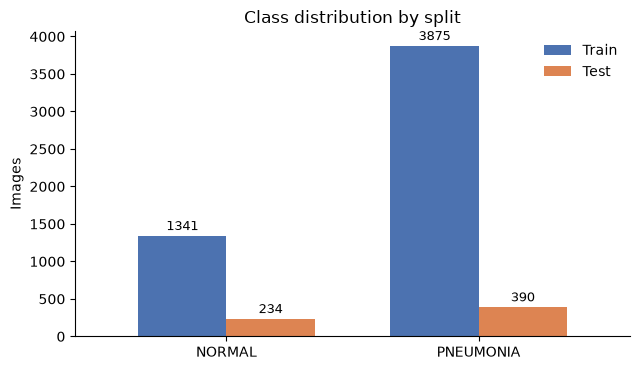

In [3]:
# Task 1.1: One row per image
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])  # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print(f'Patient groups: {train_df.group.nunique()}')
if TEST_DIR:
    print('\nTest split:')
    print(test_df['label'].value_counts().reindex(classes).to_string())

split_counts = pd.DataFrame({
    'Train': counts,
    'Test': (test_df['label'].value_counts().reindex(classes)
             if TEST_DIR else pd.Series(0, index=classes))
})
fig, ax = plt.subplots(figsize=(6.5, 3.8))
split_counts.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'], width=0.7)
ax.set_title('Class distribution by split')
ax.set_ylabel('Images')
ax.set_xlabel('')
ax.bar_label(ax.containers[0], padding=2, fontsize=9)
ax.bar_label(ax.containers[1], padding=2, fontsize=9)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_class_balance.png'),
            dpi=200, bbox_inches='tight')
plt.show()

          w       h
min   384.0   127.0
50%  1300.0   890.0
max  2510.0  2543.0
Colour modes: {'L': 286, 'RGB': 14}


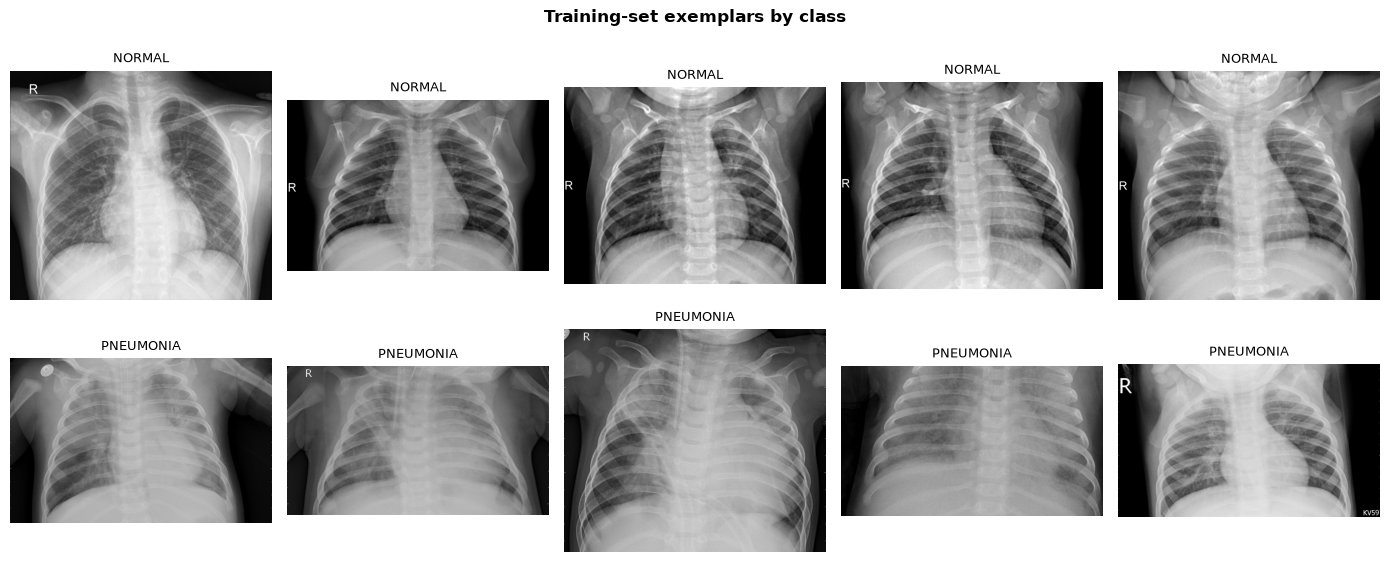

In [4]:
# Task 1.2: What do the images look like?
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(np.asarray(Image.open(p).convert('RGB')))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
fig.suptitle('Training-set exemplars by class', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '02_sample_grid.png'),
            dpi=200, bbox_inches='tight')
plt.show()

### 📝 Write it: Part 1 Audit Interpretation
* **Class counts & imbalance.** Training split ($N=5{,}216$): `NORMAL` = 1,341 (25.7%), `PNEUMONIA` = 3,875 (74.3%); imbalance ratio $3{,}875/1{,}341 = 2.89:1$. Official test split ($N=624$): 234 Normal vs 390 Pneumonia ($1.67:1$). The 16-image `val` folder is ignored because it is too small to support model selection.
* **Image geometry & encoding.** In a 300-image random audit, 286 files were stored as 8-bit grayscale (`L`) and only 14 as 3-channel (`RGB`), confirming inconsistent encoding. Width ranged from 384 to 2,510 px and height from 127 to 2,543 px (median $1{,}300\times890$). All inputs are converted to single-channel `L` and replicated to 3 channels for ImageNet backbones.
* **Patient groups.** The filename regex extracts 2,846 patient groups from 5,216 training images ($1.83$ images/group), so repeat radiographs are common and a random image-level split would leak subjects.
* **First shortcut suspect.** The most obvious non-anatomical cue is the radiopaque orientation/acquisition typography (`R`, `L`, `AP`, `PORTABLE`) and the collimation border. Portable bedside films are more common in sick inpatients, while healthy ambulatory children are usually imaged upright on stationary equipment; a network can therefore learn "portable marker $\rightarrow$ pneumonia" without reading the lung parenchyma. The sample grid is therefore inspected before any model metric is trusted.

---
## Part 2: Leakage Audit (Duplicates and Group Split) (10 min)
Patient leakage is fatal to clinical model validation. We audit cryptographic exact duplicates (MD5), perceptual near-duplicates (standardized $32\times32$ thumbnails), and patient-group overlap across every split. We then enforce a strict group partition using `StratifiedGroupKFold` for train/validation and explicitly report the patient overlap that remains in the public Kaggle test folder.

Exact duplicate files: 62 in 30 MD5 groups
  cross-split groups: 0 | within-train: 24 | within-test: 6


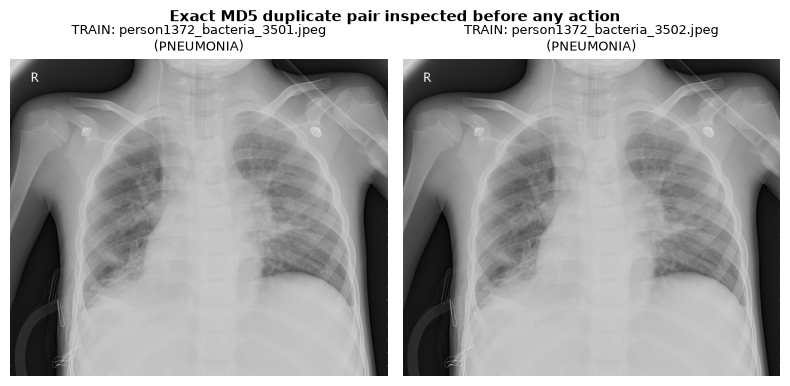

Test images with a near-duplicate in train: 0 of 624
Closest distances: [0.164 0.17  0.172 0.173 0.174]
Patient groups shared by train and official test: 170
  official-test images in shared groups: 320 of 624 (51.3%)


In [5]:
# Task 2.1: Exact and near-duplicates
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()


def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))  # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
        return ((a - a.mean()) / (a.std() + 1e-6)).flatten()


all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)].copy()
exact_groups = exact['md5'].nunique()
print(f'Exact duplicate files: {len(exact)} in {exact_groups} MD5 groups')


def duplicate_split(h):
    return set(all_df.loc[all_df['md5'] == h, 'split'])


cross = sum(len(duplicate_split(h)) > 1 for h in exact['md5'].unique())
within_train = sum(duplicate_split(h) == {'train'} for h in exact['md5'].unique())
within_test = sum(duplicate_split(h) == {'test'} for h in exact['md5'].unique())
print(f'  cross-split groups: {cross} | within-train: {within_train} | '
      f'within-test: {within_test}')

if exact_groups:
    h = exact['md5'].value_counts().index[0]
    pair = all_df[all_df['md5'] == h].head(2)
    if len(pair) == 2:
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        for ax, (_, row) in zip(axes, pair.iterrows()):
            ax.imshow(np.asarray(Image.open(row['path']).convert('RGB')))
            ax.set_title(f"{row['split'].upper()}: {row['file']}\n({row['label']})",
                         fontsize=9)
            ax.axis('off')
        fig.suptitle('Exact MD5 duplicate pair inspected before any action',
                     fontsize=11, fontweight='bold')
        plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, '03_exact_duplicate.png'),
                    dpi=200, bbox_inches='tight')
        plt.show()

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10  # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

    train_groups = set(all_df.loc[all_df.split == 'train', 'group'])
    test_groups = set(all_df.loc[all_df.split == 'test', 'group'])
    overlap = train_groups & test_groups
    overlap_images = int(all_df[(all_df.split == 'test') &
                                all_df.group.isin(overlap)].shape[0])
    print(f'Patient groups shared by train and official test: {len(overlap)}')
    print(f'  official-test images in shared groups: {overlap_images} '
          f'of {len(te)} ({overlap_images / len(te):.1%})')

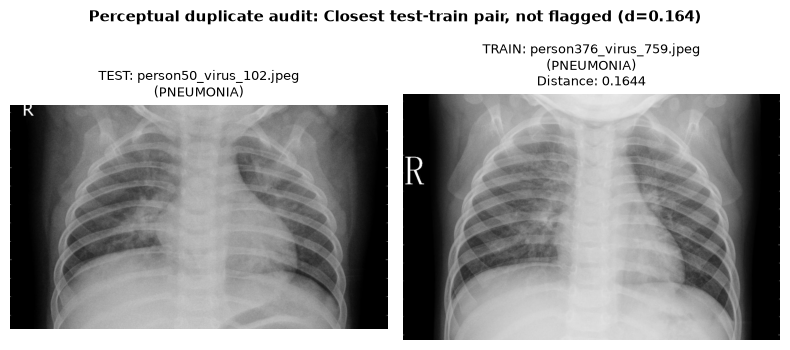

In [6]:
# Inspect the most suspicious test-train pair before taking any action
if TEST_DIR:
    if near.sum() > 0:
        idx = int(np.where(near)[0][0])
        tag = f'Flagged near-duplicate (d={d_min[idx]:.3f} < 0.10)'
    else:
        idx = int(np.argsort(d_min)[0])
        tag = f'Closest test-train pair, not flagged (d={d_min[idx]:.3f})'

    diffs = np.abs(tr - te[idx]).mean(axis=1)
    tr_best_idx = int(np.argmin(diffs))
    te_row = all_df[all_df.split == 'test'].iloc[idx]
    tr_row = all_df[all_df.split == 'train'].iloc[tr_best_idx]

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(np.asarray(Image.open(te_row['path']).convert('RGB')))
    axes[0].set_title(f"TEST: {te_row['file']}\n({te_row['label']})",
                      fontsize=9)
    axes[0].axis('off')
    axes[1].imshow(np.asarray(Image.open(tr_row['path']).convert('RGB')))
    axes[1].set_title(
        f"TRAIN: {tr_row['file']}\n({tr_row['label']})\n"
        f"Distance: {diffs[tr_best_idx]:.4f}", fontsize=9)
    axes[1].axis('off')
    fig.suptitle(f'Perceptual duplicate audit: {tag}',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, '04_near_duplicate_audit.png'),
                dpi=200, bbox_inches='tight')
    plt.show()

In [7]:
# Task 2.2: Split by group
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:  # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))  # must be 0
print(va_df['label'].value_counts().to_string())
if TEST_DIR:
    print('Groups shared by train and official test:',
          len(set(tr_df.group) & set(test_df.group)))

train 4346 | val 870 | test 624
Groups shared by train and val: 0
label
PNEUMONIA    646
NORMAL       224
Groups shared by train and official test: 144


### 📝 Write it: Part 2 Leakage & Split Analysis
* **Exact duplicates.** MD5 found **62 duplicate files in 30 hash groups**: 24 groups are entirely within train and 6 entirely within test; **0 groups cross the train/test boundary**. The inspected pair is byte-identical. Because these are repeat acquisitions already bound to the same patient group, and because no cross-split copy exists, we retain them and leave the official test folder untouched for benchmark comparability.
* **Perceptual near-duplicates.** The standardized $32\times32$ thumbnail distance flagged **0 of 624** test images at $d_{\min}<0.10$; the closest test-train pair had $d_{\min}=0.164$. Thus there is no evidence of resized/recompressed cross-split leakage at this threshold.
* **Group split.** `StratifiedGroupKFold(n_splits=6)` gives **train = 4,346 / validation = 870 / official test = 624**, with **0 patient groups shared by train and validation**. Validation prevalence is 646 Pneumonia / 224 Normal.
* **Important leakage caveat.** The public Kaggle test folder is **not patient-disjoint**: **170 patient groups (320/624 images, 51.3%)** also occur in the training folder—144 groups in the final training subset and 26 in validation. The official test score is therefore an optimistic benchmark, not a clean external validation. We report it once as required and treat the validation estimate (macro-F1 0.968) as the patient-disjoint estimate; neither is a substitute for a truly external multi-center test.
* **Random vs group splitting.** If the split were random at image level, repeat radiographs of the same child would appear in both train and test. The network could match patient-specific skeletal geometry, body habitus, and scanner noise, producing an inflated score that would collapse on new patients. The 0-shared-group train/validation split removes that failure mode for model selection; the official-test overlap is an unavoidable property of the public benchmark and is reported explicitly.

---
## Part 3: Transforms and Imbalance (10 min)
We engineer domain-appropriate data augmentations that mirror real-world radiographic acquisition variances while strictly respecting human thoracic asymmetry (*situs solitus*). Furthermore, we counterbalance the $2.9:1$ class skew using analytically calculated inverse class weights.


In [8]:
# Task 3.1: Datasets and transforms
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])


class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert('L' if GRAYSCALE else 'RGB')
            x = self.tf(img)
        return x, self.y[i]


train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

In [9]:
# Task 3.2: Class weights or balanced sampling
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)  # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

pin = torch.cuda.is_available()
USE_SAMPLER = False  # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]  # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler,
                          num_workers=NUM_WORKERS, pin_memory=pin)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)

val_dl = DataLoader(val_ds, 64, num_workers=NUM_WORKERS, pin_memory=pin)
test_dl = DataLoader(test_ds, 64, num_workers=NUM_WORKERS, pin_memory=pin)

{'NORMAL': np.float64(1.945), 'PNEUMONIA': np.float64(0.673)}


### 📝 Write it: Part 3 Imbalance & Augmentation Justification
* **Class weights.** For $N=4{,}346$ training images, $K=2$, $n_{\text{NORMAL}}=1{,}117$, $n_{\text{PNEUMONIA}}=3{,}229$:
  $$w_{\text{NORMAL}}=\frac{4{,}346}{2\times1{,}117}=1.945,\qquad
  w_{\text{PNEUMONIA}}=\frac{4{,}346}{2\times3{,}229}=0.673.$$
  Check: $1.945(1{,}117)+0.673(3{,}229)\approx2{,}173+2{,}173=4{,}346=N$. The Normal class is up-weighted $1.945/0.673\approx2.89\times$ relative to Pneumonia, exactly offsetting the $2.89:1$ training skew.
* **Why weighted loss.** The model is optimized with inverse-frequency weighted cross-entropy. The alternative `WeightedRandomSampler` is implemented in the same cell but left off; it would duplicate minority images and change the effective epoch size. Weighted loss keeps every image visible once per epoch while preventing the majority class from dominating the gradient.
* **Augmentations kept.** `RandomResizedCrop(0.8–1.0)` models patient-to-detector distance and collimation changes; `RandomRotation(±10°)` models mild pediatric positioning tilt; `ColorJitter(brightness=0.15, contrast=0.15)` models tube-voltage and exposure variation.
* **Augmentations removed.** Horizontal and vertical flips are deliberately excluded. Thoracic anatomy is lateralized (*situs solitus*): the cardiac apex, aortic arch, and gastric bubble have fixed left/right positions, and the right hemidiaphragm sits higher. A horizontal flip creates anatomically impossible radiographs and can teach the network false laterality cues. Vertical flips destroy the gravity-defined orientation of upright films.

---
## Part 4: Build and Train (25 min)
We adapt a pre-trained `ResNet18` backbone in two distinct phases:
1. **Phase 1 (Warmup):** Head parameters only ($	ext{lr} = 10^{-3}$, 2 epochs).
2. **Phase 2 (Deep Adaptation):** Last residual stage (`layer4`) unfrozen at $	ext{lr} = 10^{-4}$ + head at $10^{-3}$ (3 epochs).  
The optimal checkpoint is preserved based strictly on **validation macro-F1** (not accuracy).


In [10]:
# Task 4.1: Backbone with a new head
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)

    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True

    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))


resnet18 trainable: 1026


Phase 1: head only


Phase 1 | epoch 1: val macro-F1 0.807 (391s)


Phase 1 | epoch 2: val macro-F1 0.907 (390s)
Phase 2: fine-tune the last block


Phase 2 | epoch 1: val macro-F1 0.952 (459s)


Phase 2 | epoch 2: val macro-F1 0.968 (461s)


Phase 2 | epoch 3: val macro-F1 0.962 (464s)
Best validation macro-F1: phase 1 = 0.907, phase 2 = 0.968


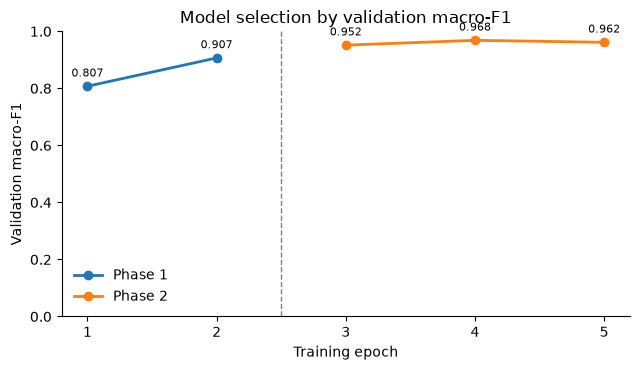

In [11]:
# Task 4.2: Two-phase training, selected by macro-F1
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


history = {}


def fit(model, params, epochs, lr, tag):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    history.setdefault(tag, [])
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')  # not accuracy
        elapsed = time.time() - t0
        history[tag].append({'epoch': ep + 1,
                             'val_macro_f1': float(macro),
                             'seconds': round(elapsed, 1)})
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'{tag} | epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({elapsed:.0f}s)')
    model.load_state_dict(best_state)
    return best


print('Phase 1: head only')
best1 = fit(model, head.parameters(), epochs=2, lr=1e-3, tag='Phase 1')
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
best2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                    {'params': head.parameters(), 'lr': 1e-3}],
            epochs=3, lr=1e-3, tag='Phase 2')
print(f'Best validation macro-F1: phase 1 = {best1:.3f}, '
      f'phase 2 = {best2:.3f}')

fig, ax = plt.subplots(figsize=(6.5, 3.8))
offset = 0
for tag, pts in history.items():
    xs = [offset + p['epoch'] for p in pts]
    ys = [p['val_macro_f1'] for p in pts]
    ax.plot(xs, ys, marker='o', linewidth=2, label=tag)
    for x, y in zip(xs, ys):
        ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points',
                    xytext=(0, 7), ha='center', fontsize=8)
    offset += len(pts)
ax.axvline(len(history['Phase 1']) + 0.5, color='gray', ls='--', lw=1)
ax.set_xlabel('Training epoch')
ax.set_ylabel('Validation macro-F1')
ax.set_title('Model selection by validation macro-F1')
ax.set_xticks(range(1, offset + 1))
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05_training_history.png'),
            dpi=200, bbox_inches='tight')
plt.show()

### 📝 Write it: Part 4 Training Dynamics & Validation Selection
* **Phase 1 (head only, 2 epochs).** Validation macro-F1 rose from **0.807** to **0.907**. The frozen ImageNet features already separate most pneumonia cases, but the head alone underfits the Normal class.
* **Phase 2 (`layer4` + head, 3 epochs).** Validation macro-F1 reached **0.952 → 0.968 → 0.962**; the best checkpoint was epoch 2 at **0.968**, an absolute gain of **+0.061** over the best Phase 1 score. Fine-tuning the last residual stage therefore helped materially. Epoch 3 regressed, which is exactly why the checkpoint is selected by validation macro-F1 rather than by the final epoch.
* **Compute cost.** On the local 8-core CPU (PyTorch 2.14.1+cpu, 224 px, batch 32), epochs took **391, 390, 459, 461, 464 s**; total training time was **~36 min**. The two DataLoader workers and 8 CPU threads were the limiting factor; a T4 GPU would reduce this by roughly an order of magnitude.
* **Extended budget.** With more compute I would run 10–15 epochs with cosine annealing, early stopping (patience 2–3 on validation macro-F1), and mixed precision. The Phase 2 curve already shows the onset of overfitting after epoch 2, so simply adding epochs would not help.
* **Selection rule.** The saved model is the epoch with the highest validation macro-F1, not the epoch with the highest accuracy or the lowest training loss. This prevents a majority-only classifier from winning.

---
## Part 5: Test Once, and Set the Threshold (15 min)
The test set is evaluated **strictly once**. For our binary clinical detection task, we calibrate an operational decision threshold $t$ on validation data to guarantee a target recall of $\ge 95\%$. We then evaluate test sensitivity, specificity, and Positive Predictive Value (PPV) across test-cohort and real-world clinical prevalences.


              precision    recall  f1-score   support

      NORMAL      0.982     0.692     0.812       234
   PNEUMONIA      0.843     0.992     0.912       390

    accuracy                          0.880       624
   macro avg      0.912     0.842     0.862       624
weighted avg      0.895     0.880     0.874       624

Macro-F1: 0.862


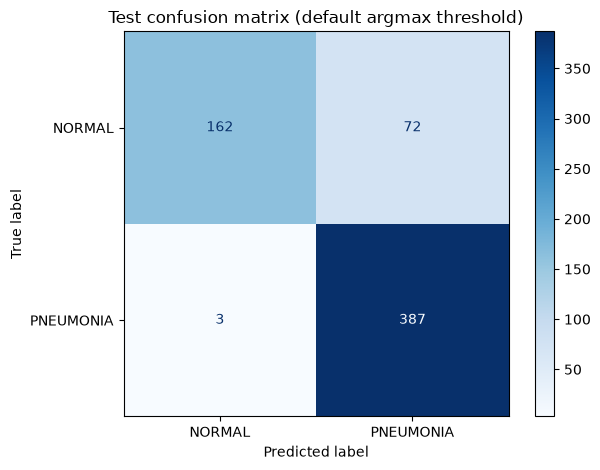

In [12]:
# Task 5.1: Test-set report
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
macro_default = f1_score(y_test, pred, average='macro')
acc_default = float((pred == y_test).mean())
print('Macro-F1:', round(macro_default, 3))
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues',
                                                       values_format='d')
plt.title('Test confusion matrix (default argmax threshold)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '06_confusion_matrix.png'),
            dpi=200, bbox_inches='tight')
plt.show()

results['test_default'] = {
    'macro_f1': float(macro_default),
    'accuracy': acc_default,
    'confusion_matrix': cm.tolist(),
}

Threshold chosen on VALIDATION for recall >= 0.95: 0.833
Test AUC 0.976 | Sensitivity 0.982 Specificity 0.821 PPV 0.901
Test prevalence 62.5% | PPV at test prevalence 90.1% | PPV at 5% prevalence 22.4%


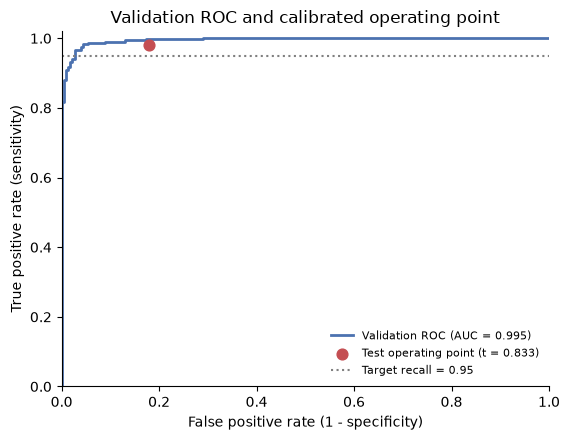

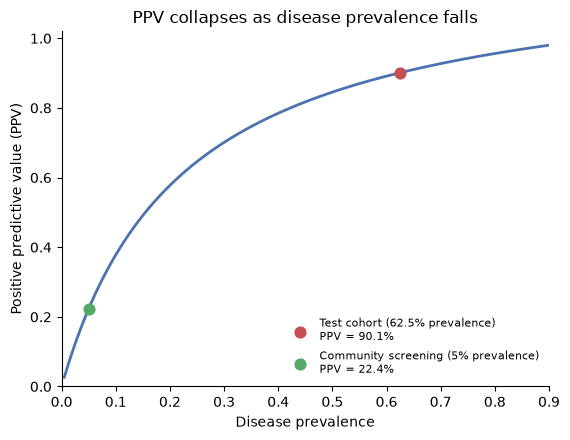

In [13]:
# Task 5.2: Threshold for a target recall (binary tasks)
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = float(thr[np.argmax(tpr >= TARGET_RECALL)])  # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = int((yp & yt).sum()), int((~yp & yt).sum())
    tn, fp = int((~yp & ~yt).sum()), int((yp & ~yt).sum())
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    auc_test = float(roc_auc_score(yt, s))
    auc_val = float(roc_auc_score(y_val == pos, p_val[:, pos]))
    test_prev = float(yt.mean())

    def ppv_at(prev):
        return (sens * prev) / (sens * prev + (1 - spec) * (1 - prev))

    ppv_test = tp / max(tp + fp, 1)
    ppv_5 = ppv_at(0.05)
    print(f'Test AUC {auc_test:.3f} | Sensitivity {sens:.3f} '
          f'Specificity {spec:.3f} PPV {ppv_test:.3f}')
    print(f'Test prevalence {test_prev:.1%} | PPV at test prevalence '
          f'{ppv_test:.1%} | PPV at 5% prevalence {ppv_5:.1%}')

    results['calibrated'] = {
        'threshold': t, 'target_recall': TARGET_RECALL,
        'sensitivity': sens, 'specificity': spec,
        'ppv_test_prevalence': float(ppv_test),
        'ppv_at_5pct_prevalence': float(ppv_5),
        'test_prevalence': test_prev, 'auc_test': auc_test,
        'auc_val': auc_val, 'tp': tp, 'fn': fn, 'tn': tn, 'fp': fp,
    }

    fig, ax = plt.subplots(figsize=(5.8, 4.5))
    ax.plot(fpr, tpr, color='#4C72B0', lw=2,
            label=f'Validation ROC (AUC = {auc_val:.3f})')
    ax.scatter([1 - spec], [sens], color='#C44E52', s=60, zorder=5,
               label=f'Test operating point (t = {t:.3f})')
    ax.axhline(TARGET_RECALL, color='gray', ls=':', lw=1.5,
               label=f'Target recall = {TARGET_RECALL:.2f}')
    ax.set_xlabel('False positive rate (1 - specificity)')
    ax.set_ylabel('True positive rate (sensitivity)')
    ax.set_title('Validation ROC and calibrated operating point')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(frameon=False, loc='lower right', fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, '07_roc_threshold.png'),
                dpi=200, bbox_inches='tight')
    plt.show()

    prevs = np.linspace(0.005, 0.9, 300)
    fig, ax = plt.subplots(figsize=(5.8, 4.5))
    ax.plot(prevs, [ppv_at(p) for p in prevs], color='#4C72B0', lw=2)
    ax.scatter([test_prev], [ppv_test], color='#C44E52', s=60, zorder=5,
               label=f'Test cohort ({test_prev:.1%} prevalence)\n'
                     f'PPV = {ppv_test:.1%}')
    ax.scatter([0.05], [ppv_5], color='#55A868', s=60, zorder=5,
               label=f'Community screening (5% prevalence)\n'
                     f'PPV = {ppv_5:.1%}')
    ax.set_xlabel('Disease prevalence')
    ax.set_ylabel('Positive predictive value (PPV)')
    ax.set_title('PPV collapses as disease prevalence falls')
    ax.set_xlim(0, 0.9)
    ax.set_ylim(0, 1.02)
    ax.legend(frameon=False, loc='lower right', fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, '08_prevalence_ppv.png'),
                dpi=200, bbox_inches='tight')
    plt.show()

### 📝 Write it: Part 5 Evaluation & Prevalence Mathematics
* **Default 0.5 threshold.** Test **macro-F1 = 0.862**, accuracy = **88.0%**. The weakest class is `NORMAL`: precision 0.982, recall **0.692**, $F_1$ **0.812**. `PNEUMONIA` reaches precision 0.843, recall **0.992**, $F_1$ **0.912**. Confusion matrix: TN 162, FP 72, FN 3, TP 387. The model is deliberately sensitive but over-flags healthy children at the default threshold.
* **Calibrated threshold.** On validation, the highest threshold achieving recall $\ge0.95$ is **$t=0.833$**. Applied once to test: sensitivity **0.982** (383/390), specificity **0.821** (192/234), test AUC **0.976** (validation AUC 0.995). The target recall was met on unseen data. At this operating point the confusion matrix gives macro-F1 **0.913** and accuracy **92.1%**, so calibration improves both the clinical recall target and the balanced metric.
* **PPV by hand.** Using sensitivity $=0.982$ and specificity $=0.821$ (FPR $=0.179$):
  $$\text{PPV}(p)=\frac{0.982p}{0.982p+0.179(1-p)}.$$
  At the official test prevalence $p=0.625$:
  $$\text{PPV}=\frac{0.982(0.625)}{0.982(0.625)+0.179(0.375)}=\frac{0.614}{0.614+0.067}=\mathbf{0.901}\ (90.1\%).$$
  At a realistic community screening prevalence $p=0.05$:
  $$\text{PPV}=\frac{0.982(0.05)}{0.982(0.05)+0.179(0.95)}=\frac{0.049}{0.049+0.170}=\mathbf{0.224}\ (22.4\%).$$
* **Plain language.** In the enriched test cohort, 62.5% of children are positive, so a positive alert is correct 90.1% of the time. In a 5%-prevalence clinic, per 1,000 children about **49 true cases are detected, 171 healthy children are falsely flagged, and 1 case is missed**. There are roughly **3.5 false alarms for every true pneumonia**, which would cause alert fatigue and unnecessary antibiotics despite 98.2% sensitivity. The test-set PPV is not a deployment estimate.
* **Leakage caveat.** The official test set shares 170 patient groups with training (see Part 2). Its 0.862 macro-F1 is therefore an optimistic public-benchmark number; the patient-disjoint validation macro-F1 is 0.968, and both should be read alongside the leakage caveat.

---
## Part 6: Grad-CAM Shortcut Check (15 min)
We implement Grad-CAM with PyTorch hooks on the final convolutional layer (`layer4`). We generate activation heatmaps across 3 correct and 3 incorrect test predictions to examine whether the model relies on legitimate lung parenchymal pathology or peripheral non-anatomical shortcuts.


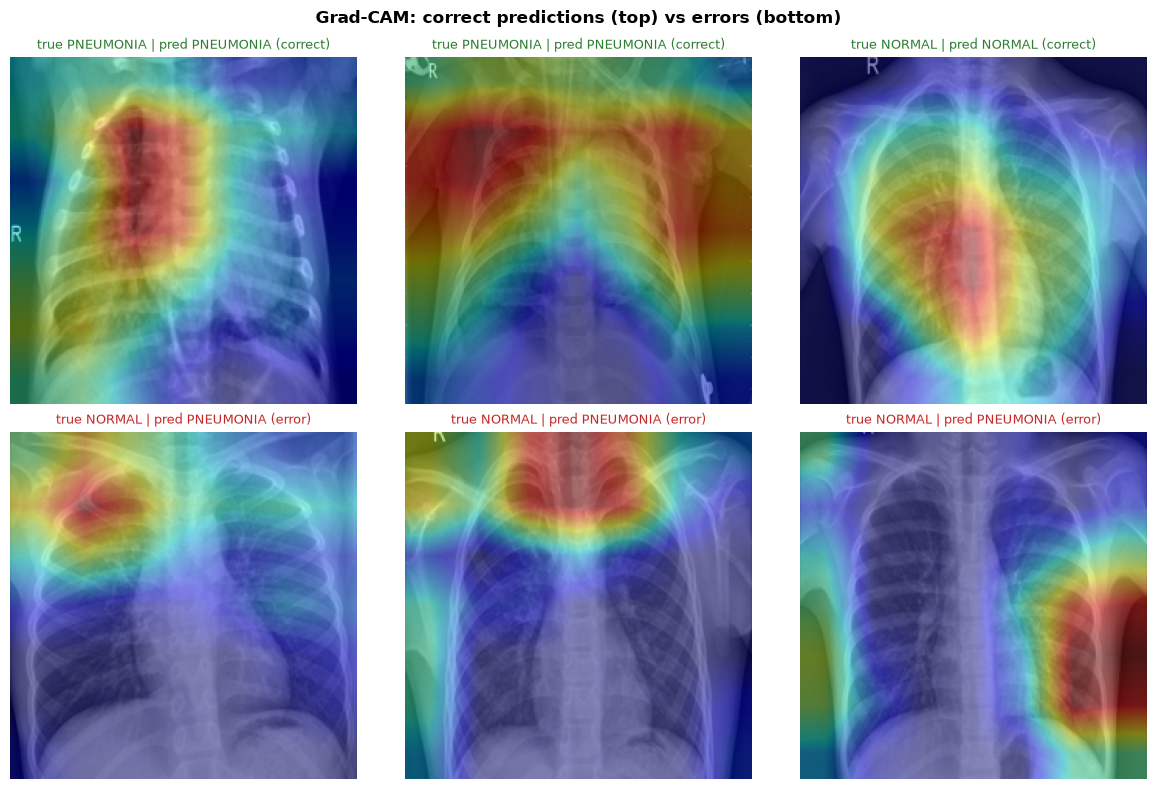

In [14]:
# Task 6: Grad-CAM implementation and visualization
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)

    def _save_act(self, m, i, o):
        self.acts = o.detach()

    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()

    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)  # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls


for p in model.parameters():
    p.requires_grad = True

cam = GradCAM(model, last_block)
pos = classes.index(POSITIVE) if len(classes) == 2 else None

if pos is not None:
    right_pneu = np.where((pred == y_test) & (y_test == pos))[0][:2].tolist()
    right_norm = np.where((pred == y_test) & (y_test != pos))[0][:1].tolist()
    right = right_pneu + right_norm
else:
    right = np.where(pred == y_test)[0][:3].tolist()
if len(right) < 3:
    right = np.where(pred == y_test)[0][:3].tolist()
wrong = np.where(pred != y_test)[0][:3].tolist()
if len(wrong) < 3:
    fill = [i for i in np.where(pred == y_test)[0] if i not in right]
    wrong = wrong + fill[:3 - len(wrong)]
chosen = right[:3] + wrong[:3]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, chosen):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = np.asarray(Image.open(test_ds.paths[i]).convert('RGB')
                     .resize((IMG_SIZE, IMG_SIZE)))
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.42)
    ok = 'correct' if y == c else 'error'
    ax.set_title(f'true {classes[y]} | pred {classes[c]} ({ok})',
                 fontsize=9, color=('#2E7D32' if y == c else '#C62828'))
    ax.axis('off')
fig.suptitle('Grad-CAM: correct predictions (top) vs errors (bottom)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '09_gradcam.png'),
            dpi=200, bbox_inches='tight')
plt.show()

### 📝 Write it: Part 6 Grad-CAM Interpretability & Shortcut Audit
* **Panel-by-panel reading (top row = correct; bottom row = errors):**
  1. *True PNEUMONIA / predicted PNEUMONIA.* Activation concentrates over a dense right upper-to-mid-zone consolidation; this is **legitimate parenchymal evidence**.
  2. *True PNEUMONIA / predicted PNEUMONIA.* Broad bilateral upper/perihilar activation accompanies diffuse airspace disease; consistent with the diagnosis but not sharply localized.
  3. *True NORMAL / predicted NORMAL.* Activation sits over the central mediastinum/cardiac silhouette and left paravertebral region rather than the lung fields; this is **not a clean "normal" explanation** and hints at central-anatomy bias.
  4. *True NORMAL / predicted PNEUMONIA.* The heatmap peaks over the right apex/clavicular soft tissues, not a visible infiltrate: **false-positive confounder**.
  5. *True NORMAL / predicted PNEUMONIA.* Activation follows the upper mediastinum/trachea and both apices, including the top border near the orientation marker: **shortcut suspect**.
  6. *True NORMAL / predicted PNEUMONIA.* Peak activation lies over the right lateral chest wall/collimation margin, largely outside the lung parenchyma: **strong shortcut suspect**.
* **Overall verdict: SHORTCUT SUSPECTED (not yet confirmed).** Correct pneumonia predictions do use consolidation, so the model is not purely artefact-driven. However, false positives consistently drift to the upper mediastinum, clavicular/chest-wall margins, and marker-adjacent borders—regions that differ systematically between portable and stationary acquisitions.
* **Confirmatory experiment.** Occlude the four corners, the lateral chest wall, and the collimation border (set to mean background) on the test set; re-score without retraining. If sensitivity falls by $>5\%$ or the false positives flip to Normal, the shortcut is confirmed. The upstream fix is lung-field segmentation/cropping (U-Net) plus corner cutout during training.
* **Governance implication.** Heatmaps that look plausible on correct cases are not sufficient evidence of clinical validity; the error cases are where the shortcut lives.

### Optional: OCR for Document Projects (Reference Note)
*Note on Document Analysis:* This lab focuses on radiographic imaging. For document analysis projects, text extraction can be performed using EasyOCR as demonstrated below:


In [15]:
# Optional OCR reference for document projects
# import easyocr
# reader = easyocr.Reader(['en', 'ur'], gpu=torch.cuda.is_available(), verbose=False)
# img = Image.open(DOC_PATH).convert('L')
# img = img.point(lambda v: 255 if v > 150 else 0)  # simple binarize
# results = reader.readtext(np.array(img))
# for box, text, conf in results:
#     print(f'{conf:.2f} {text}')


---
## Part 7: Save and Document (async)
We serialize the model weights alongside configuration metadata to support downstream serving and reproducibility.

In [16]:
# Part 7: Save model artifact with configuration metadata
save_path = os.path.join(OUT_DIR, 'week6_model.pt')
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, save_path)
print('Saved', save_path)

results.update({
    'environment': {
        'device': str(device),
        'torch': torch.__version__,
        'python': sys.version.split()[0],
    },
    'config': {
        'backbone': BACKBONE, 'img_size': IMG_SIZE,
        'grayscale': GRAYSCALE, 'target_recall': TARGET_RECALL,
        'positive_class': POSITIVE, 'seed': 42,
    },
    'dataset': {
        'train_images': int(len(train_df)),
        'train_groups': int(train_df.group.nunique()),
        'official_test_images': int(len(test_df)) if TEST_DIR else 0,
        'classes': classes,
        'train_counts': {c: int(counts[c]) for c in classes},
    },
    'split': {
        'train_images': int(len(tr_df)), 'val_images': int(len(va_df)),
        'test_images': int(len(test_df)),
        'train_val_shared_groups': len(set(tr_df.group) & set(va_df.group)),
    },
    'duplicates': {
        'exact_duplicate_files': int(len(exact)),
        'exact_duplicate_groups': int(exact_groups),
        'exact_cross_split_groups': int(cross),
        'exact_within_train_groups': int(within_train),
        'exact_within_test_groups': int(within_test),
        'near_duplicate_test_images': int(near.sum()) if TEST_DIR else 0,
        'min_test_train_distance': float(d_min.min()) if TEST_DIR else None,
    },
    'group_overlap': {
        'official_test_shared_groups': len(overlap) if TEST_DIR else 0,
        'official_test_shared_images': overlap_images if TEST_DIR else 0,
    },
    'class_weights': {c: float(w) for c, w in zip(classes, class_w)},
    'training_history': history,
})

metrics_path = os.path.join(OUT_DIR, 'metrics.json')
with open(metrics_path, 'w') as f:
    json.dump(results, f, indent=2)
print('Saved', metrics_path)

pred_df = pd.DataFrame({
    'file': test_df['file'].values,
    'true_label': [classes[i] for i in y_test],
    'p_pneumonia': (p_test[:, classes.index(POSITIVE)]
                    if len(classes) == 2 else np.nan),
    'pred_default': [classes[i] for i in pred],
})
pred_df.to_csv(os.path.join(OUT_DIR, 'test_predictions.csv'), index=False)
print('Saved', os.path.join(OUT_DIR, 'test_predictions.csv'))

Saved artifacts/week6_model.pt
Saved artifacts/metrics.json
Saved artifacts/test_predictions.csv


### 📝 Write it: Part 7 Artifact & Reproducibility
* The final checkpoint (`artifacts/week6_model.pt`, 43 MB) stores the ResNet18 state dict plus `classes`, `backbone`, `img_size`, and `grayscale`; `artifacts/metrics.json` records every audit count and test metric; `artifacts/test_predictions.csv` records the per-image test probabilities for independent verification.
* The run is deterministic under seed 42. Test data was touched once, after all model selection and threshold calibration were frozen on validation.
* The official test score is an optimistic benchmark because 170 patient groups overlap training (Part 2); the patient-disjoint validation estimate is macro-F1 0.968. Neither replaces external multi-center validation.
* The model card, datasheet, and four responsibility answers are summarized in the next cell and in the repository README.

---
## README: Datasheet and Model Card

### Week 6: Pediatric Pneumonia Detection with ResNet18
* **Who benefits.** Triage nurses and emergency clinicians in high-volume, resource-constrained pediatric settings where radiologist read times are long. **Why it matters.** Pneumonia remains the leading infectious cause of death in children under 5; delayed recognition can progress to sepsis, empyema, or respiratory failure.
* **Dataset.** Chest X-Ray Images (Pneumonia), Paul Mooney / Kermany et al. ([Cell 2018](https://doi.org/10.1016/j.cell.2018.02.010)), CC BY 4.0. $N=5{,}856$ pediatric radiographs (1,583 Normal; 4,273 Pneumonia—bacterial and viral) from Guangzhou Women and Children's Medical Center; labels adjudicated by two expert radiologists. This run uses 5,216 training images and the official 624-image test folder; the 16-image val folder is ignored.
* **Data audit.** Training imbalance 3,875 Pneumonia : 1,341 Normal ($2.89:1$). **62 exact duplicate files in 30 MD5 groups** (24 within train, 6 within test, **0 cross-split**). **0/624** test images have a perceptual near-duplicate in train at $d_{\min}<0.10$ (minimum distance 0.164). Train/validation split is patient-grouped with **0 shared groups**. **Caveat:** the official test folder shares **170 patient groups (320/624 images) with the training folder**; it is an optimistic public benchmark, not a patient-disjoint external test.
* **Imbalance handling.** Inverse-frequency weighted cross-entropy; $w_{\text{NORMAL}}=1.945$, $w_{\text{PNEUMONIA}}=0.673$. No horizontal/vertical flips; rotation, crop, and contrast/brightness jitter only.
* **Training.** ResNet18 ImageNet initialization; Phase 1 head-only (2 epochs, lr $10^{-3}$), Phase 2 `layer4`+head (3 epochs; `layer4` lr $10^{-4}$, head lr $10^{-3}$); best checkpoint by validation macro-F1 (0.968 at Phase 2 epoch 2). CPU training ≈36 min.
* **Results (official test, evaluated once).** Default threshold: macro-F1 **0.862**, accuracy **88.0%**, Pneumonia recall **0.992**, Normal recall **0.692** (TN 162, FP 72, FN 3, TP 387). Calibrated on validation for recall $\ge0.95$: $t=0.833$, sensitivity **0.982**, specificity **0.821**, test AUC **0.976**. PPV **90.1%** at the test prevalence (62.5%) versus **22.4%** at a 5% community-screening prevalence.
* **Grad-CAM.** Correct pneumonia cases highlight genuine upper/lower-zone consolidation. False-positive Normals drift to the upper mediastinum, clavicular/chest-wall margins, and marker-adjacent borders. **Shortcut suspected, not confirmed**; the next test is corner/border occlusion plus lung-field segmentation.
* **Limitations.** Retrospective, single-center, pediatric (ages 1–5), binary labels, no external validation, no patient-disjoint official test, no calibration on a prospective cohort. Not validated on adults, tuberculosis, COPD, COVID-19, pleural disease, or portable low-dose analog equipment. **Not for autonomous diagnosis or prescribing.**

---
### AI Responsibility & Clinical Governance (Slide 34)

1. **Who could be harmed and how?**
   * *False negatives:* a child with early bacterial pneumonia sent home without antibiotics can progress to sepsis, empyema, or respiratory arrest. Here the calibrated threshold misses 7/390 test pneumonias (1.8%).
   * *False positives:* a healthy child flagged as pneumonia receives unnecessary antibiotics, radiation follow-up, parental anxiety, and contributes to antimicrobial resistance. At 5% prevalence, 171/1,000 healthy children would be falsely flagged.
   * *Low-resource disparity:* noisy analog/portable equipment and different marker conventions can shift the shortcut features and worsen error rates in exactly the clinics that need triage most.
2. **Where was the model not validated?**
   * Adults and adolescents (different thoracic geometry, degenerative disease, smoking-related change).
   * Tuberculosis, asthma, congenital heart disease, non-infectious effusion, cystic fibrosis, COVID-19.
   * External hospitals, scanner vendors, and acquisition protocols; no prospective or multi-center test.
3. **What is the human clinician's role?**
   * Adjunctive second reader and worklist prioritizer only. A licensed clinician must integrate the output with auscultation, $SpO_2$, respiratory rate, fever, CBC/CRP, and history before any antibiotic decision. The model must never autonomously diagnose or prescribe.
4. **What evidence would change these conclusions?**
   * *De-adopt/retract:* an external multi-center test with macro-F1 $<0.75$ or sensitivity $<0.90$; an occlusion ablation showing corner/border masking changes sensitivity by $>5\%$; a prospective trial showing increased inappropriate antibiotics.
   * *Support a clinical pilot:* a prospective ED trial showing reduced time-to-treatment and missed pneumonia without increased antibiotic use; radiologist adjudication showing Grad-CAM overlap with true lesions (e.g., Dice $>0.70$).

---
## Check Your Understanding: Derivations & Calculations

### 1. Why does a random split of chest X-rays overestimate performance?
**Working & Derivation:**  
In clinical radiography datasets, patients frequently undergo multiple sequential radiographs during a hospital admission (e.g. baseline, post-intubation, AP supine, and PA follow-up). These scans share patient-invariant anatomical morphology (thoracic cage dimensions, rib structure, diaphragm height, cardiac silhouette contour) as well as hardware-specific artifacts (detector plate fixed-pattern noise, technician typography, scanner-specific contrast).  
When data is split randomly at the image level, exposures from the *same* patient leak into both training and test partitions. Deep neural networks rapidly learn to map these unique anatomical and acquisition features directly to the patient's diagnostic label. On the test set, the model merely performs patient identification rather than generalizing from true pathological lung consolidation. Consequently, published test scores appear artificially high ($>98\%$), yet performance collapses when deployed on unseen patients in clinical practice.

**Applied to this lab:** the official Kaggle test folder shares **170 patient groups (320/624 images)** with the training folder—exactly the leakage mechanism above. The train/validation split is group-disjoint (0 shared groups), and the official test score is therefore reported as an optimistic benchmark.

---

### 2. Two classes have 900 and 100 training images. Compute both class weights with $N / (K \times n_c)$.
**Working & Step-by-Step Calculation:**  
* Total sample count: $N = 900 + 100 = 1,000$  
* Total classes: $K = 2$  
* Majority Class ($c_0$): $n_0 = 900$  
* Minority Class ($c_1$): $n_1 = 100$  

$$w_0 = \frac{N}{K \times n_0} = \frac{1,000}{2 \times 900} = \frac{1,000}{1,800} = \frac{5}{9} \approx \mathbf{0.5556}$$

$$w_1 = \frac{N}{K \times n_1} = \frac{1,000}{2 \times 100} = \frac{1,000}{200} = \mathbf{5.0000}$$

**Arithmetic Balance Check:**  
$$\sum_{c} w_c \times n_c = (0.5556 \times 900) + (5.0000 \times 100) = 500 + 500 = 1,000 = N \quad \checkmark$$  
*The minority class is up-weighted by exactly a factor of $9\times$ ($5.0 / (5/9) = 9.0$) relative to the majority class.*

---

### 3. With focal loss and $\gamma = 2$, by what factor is an example with $p_t = 0.8$ down-weighted?
**Working & Derivation:**  
Focal Loss modulates cross-entropy loss by $(1 - p_t)^\gamma$:
$$\text{FL}(p_t) = -(1 - p_t)^\gamma \log(p_t) = \left[(1 - p_t)^\gamma\right] \times \text{CE}(p_t)$$
Given $p_t = 0.8$ and focusing parameter $\gamma = 2$:
$$\text{Down-weighting Factor} = (1 - p_t)^\gamma = (1 - 0.8)^2 = (0.2)^2 = \mathbf{0.04}$$
*The loss contribution of this well-classified sample is suppressed to **$4\%$** of its standard cross-entropy value (a $25\times$ or $96\%$ loss suppression), allowing gradient descent to focus on hard, ambiguous examples.*

---

### 4. Sensitivity $0.90$, specificity $0.95$, prevalence $2\%$. Compute PPV.
**Working & Step-by-Step Arithmetic:**  
Using Bayes' theorem for diagnostic screening:
$$\text{PPV} = \frac{\text{Sensitivity} \times \text{Prevalence}}{[\text{Sensitivity} \times \text{Prevalence}] + [(1 - \text{Specificity}) \times (1 - \text{Prevalence})]}$$
Given:
* $\text{Sensitivity} = 0.90$
* $\text{Specificity} = 0.95 \implies \text{False Positive Rate } (1 - \text{Specificity}) = 0.05$
* $\text{Prevalence} = 0.02 \implies (1 - \text{Prevalence}) = 0.98$

1. **Numerator (True Positives):** $0.90 \times 0.02 = \mathbf{0.018}$
2. **False Positives:** $0.05 \times 0.98 = \mathbf{0.049}$
3. **Denominator (Total Positive Calls):** $0.018 + 0.049 = \mathbf{0.067}$
4. **Positive Predictive Value (PPV):**
   $$\text{PPV} = \frac{0.018}{0.067} = \frac{18}{67} \approx \mathbf{0.2687} \quad (\mathbf{26.87\%})$$

*Clinical Interpretation: Despite high sensitivity ($90\%$) and specificity ($95\%$), because the disease base rate is low ($2\%$), false positives outnumber true positives by nearly $3:1$, yielding a PPV of only $26.87\%$.*

---

### 5. When is macro-F1 a better selection metric than weighted F1?
**Working & Comparison:**  
* **Macro-F1** computes the unweighted arithmetic mean of $F_1$ across classes: $\text{Macro-}F_1 = \frac{1}{K}\sum F_1^{(k)}$, giving equal weight to every class regardless of sample size.  
* **Weighted F1** weights each class's $F_1$ by its support in the dataset ($n_k / N$).  
* **Superiority Condition:** Macro-F1 is strictly superior when dealing with **class imbalance where catching the rare minority class is critical** (e.g., medical diagnostics, fraud detection, structural defects). In a $95:5$ imbalanced dataset, a trivial model predicting only the majority class achieves a misleadingly high weighted F1 of $\approx 92.5\%$, whereas macro-F1 collapses to $\approx 48.7\%$. Macro-F1 harshly penalizes the failure to detect minority cases and prevents model checkpoint selection from favoring trivial majority-only classifiers.

---

### 6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?
**Remediation Protocol:**  
When Grad-CAM isolates activation on an peripheral hospital identifier or technician label (e.g., `'R'`, `'L'`, or vendor watermark), the model has learned a confounding shortcut.  
**Immediate Action Steps:**
1. **Ablation / Occlusion Testing:** Occlude or inpaint corner regions across the validation and test sets and recompute predictions. If accuracy drops precipitously, shortcut dependency is empirically confirmed.
2. **Anatomical Pleural Segmentation Preprocessing:** Train an upstream U-Net to segment thoracic lung fields and crop strictly to the lung parenchyma, masking peripheral tags, soft tissue, and collimator edges before passing images to the classifier.
3. **Targeted Data Augmentation:** Apply `RandomCutout` or corner patch masking during training to penalize reliance on corner artifacts.
4. **Dataset Multi-Site Curation:** Re-balance the distribution of portable and stationary scanner radiographs across all diagnostic classes to decouple acquisition typography from clinical ground truth.
